# Objectif 

Recherche d'une situation passive favorable à la démonstration de la méthode de localisation dans le cas library actif / event passif.

Date de création : 28/10/2026

In [30]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from datetime import datetime

In [31]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *


# Chargement des données 

## Données de la portion pour la librairie 
Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. 

In [32]:
portion_id = 5
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = xr.open_datatree(fpath, auto_complex=True)
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  /home/program/ubf_tools/real_data_analysis/acouplane/d...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2313, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 19kB ...
│   │           atl_lat                 (atl_datetime) float64 19kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               5
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   │           obs_position:             OBS position corrected using LMS inversion.
│   │           obs_position_filepath:    C:\Users\baptiste.menetrier\Desktop\devPy\phd\r...
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2120, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:1...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T11:1...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 17kB ...
│   │           atl_lat                 (atl_datetime) float64 17kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 45kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 45kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 45kB ...
│   │       Attributes:
│   │           description:              Posi

## Données de positions 
Toutes les données disponibles : 

* Données AIS 
* Données de l'ATALANTE 

In [33]:
ds_pos = xr.open_dataset(ACOUPLANE_POSITIONS_NC_FPATH)
print(ds_pos)

<xarray.Dataset> Size: 525MB
Dimensions:         (rcv_id: 7, atl_datetime: 563739, mmsi: 526,
                     ais_datetime: 60447, src_datetime: 33608)
Coordinates:
  * rcv_id          (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
  * atl_datetime    (atl_datetime) datetime64[ns] 5MB 2026-02-24 ... 2026-03-...
  * ais_datetime    (ais_datetime) datetime64[ns] 484kB 2026-02-23T23:59:50 ....
  * src_datetime    (src_datetime) datetime64[ns] 269kB 2026-02-24T20:14:06.6...
Dimensions without coordinates: mmsi
Data variables: (12/13)
    rcv_lon         (rcv_id) float64 56B ...
    rcv_lat         (rcv_id) float64 56B ...
    rcv_immersion   (rcv_id) int16 14B ...
    atl_lon         (atl_datetime) float64 5MB ...
    atl_lat         (atl_datetime) float64 5MB ...
    ais_lon         (mmsi, ais_datetime) float64 254MB ...
    ...              ...
    tir_SEGD        (src_datetime) int64 269kB ...
    tir_ECOS        (src_datetime) int64 269kB ...
    tir_src_lon     (src_date

# Étude des positions des sources passives 

## Définition d'une zone d'intérêt

On commence par définir la zone de recherche. Cette zone correspond à la zone du maillage de la librairie + un petit offset pour mieux visualiser la trajectoire des sources avant et après avoir traversé la grille. 

In [34]:
# Step 1: select AIS pos in the area of interest
lon_offset_percentage = lat_offset_percentage = 0.001

lon_min, lon_max = np.min([
    node.to_dataset().tir_src_lon.min() for _, node in portion.position.children.items()
]) * (1 - lon_offset_percentage / 2), np.max(
    [
    node.to_dataset().tir_src_lon.max() for _, node in portion.position.children.items()
]
) * (1 + lon_offset_percentage / 2)
lat_min, lat_max = np.min([
    node.to_dataset().tir_src_lat.min() for _, node in portion.position.children.items()
]) * (1 - lat_offset_percentage / 2), np.max(
    [
    node.to_dataset().tir_src_lat.max() for _, node in portion.position.children.items()
]
) * (1 + lat_offset_percentage / 2)
lon_min, lon_max, lat_min, lat_max

(np.float64(5.919009015),
 np.float64(5.965350184499999),
 np.float64(42.973826338),
 np.float64(43.07525886599999))

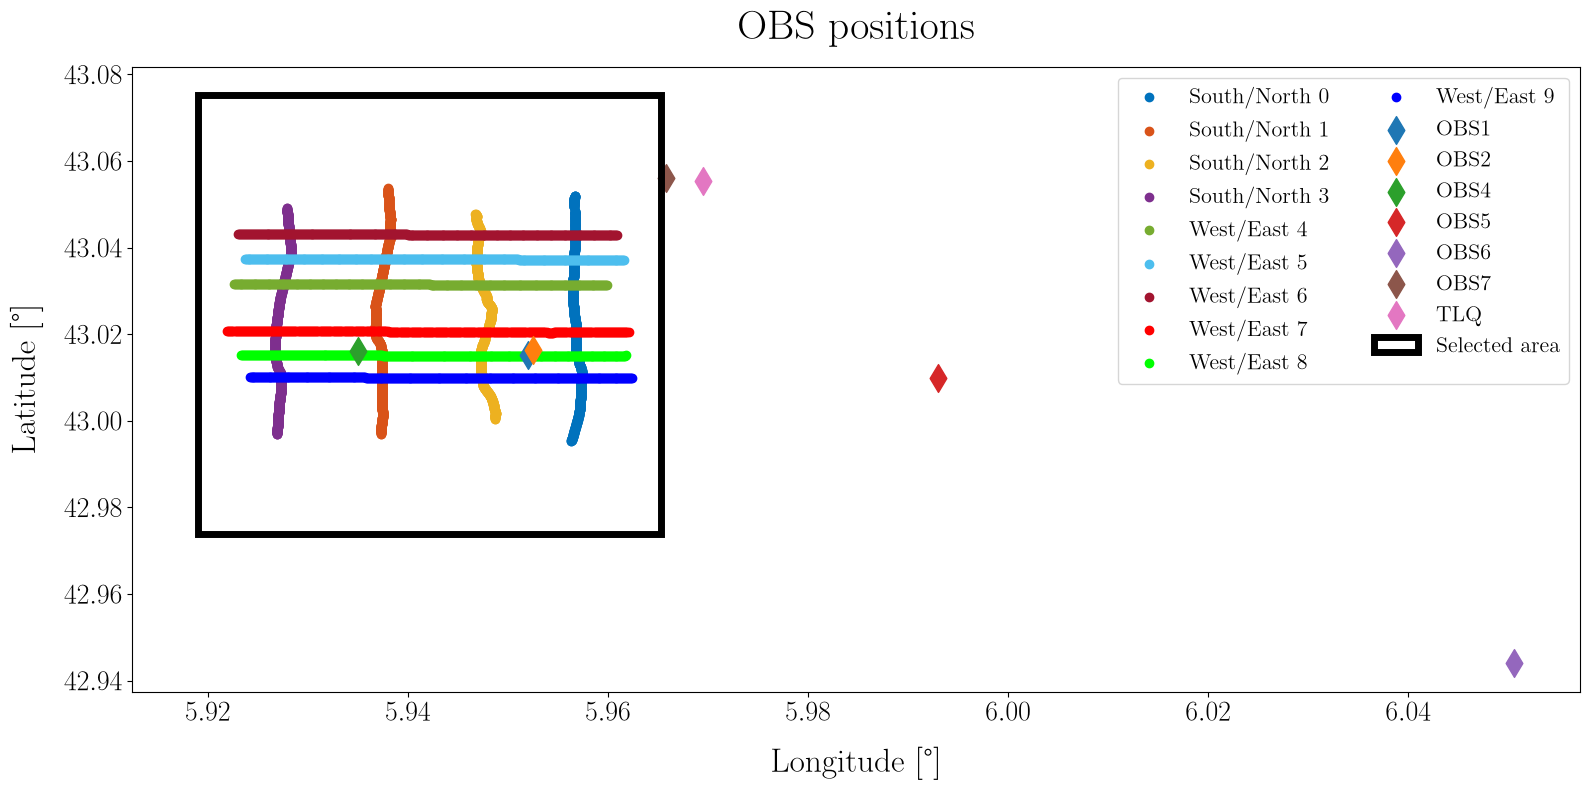

In [35]:
# Illustrate on map
fig, ax = plot_portion_tir_pos(portion_tree=portion)
ax.add_patch(
    Rectangle(
        (lon_min, lat_min),
        lon_max - lon_min,
        lat_max - lat_min,
        fc="none",
        ec="k",
        lw=5,
        label="Selected area",
    )
)
ax.legend()
legend = ax.get_legend()

if legend is not None:
    handles = legend.legend_handles
    labels = [text.get_text() for text in legend.get_texts()]

    legend.remove()

    ax.legend(
        handles,
        labels,
        loc="upper right",
        fontsize=16,
        ncols=2,
    )

## Position AIS 

On extrait ensuite les positions AIS qui passe dans la boite définie. 

In [36]:
ds_ais = ds_pos.copy().drop_vars(
    [v for v in list(ds_pos.variables) if v not in ["ais_lon", "ais_lat", "ais_datetime"]]
)

mask = (
    (ds_ais["ais_lon"] >= lon_min)
    & (ds_ais["ais_lon"] <= lon_max)
    & (ds_ais["ais_lat"] >= lat_min)
    & (ds_ais["ais_lat"] <= lat_max)
)

# Mask and drop coordinates that have no positions in the area
ds_ais_in_area = (
    ds_ais.where(mask).dropna("ais_datetime", how="all").dropna("mmsi", how="all")
)
# Add mmsi to ease selection
ds_ais_in_area = ds_ais_in_area.assign_coords(mmsi=np.arange(ds_ais_in_area.sizes["mmsi"]))
ds_ais_in_area

<xarray.Dataset> Size: 17MB
Dimensions:       (mmsi: 78, ais_datetime: 13204)
Coordinates:
  * mmsi          (mmsi) int64 624B 0 1 2 3 4 5 6 7 ... 70 71 72 73 74 75 76 77
  * ais_datetime  (ais_datetime) datetime64[ns] 106kB 2026-02-24T03:27:00 ......
Data variables:
    ais_lon       (mmsi, ais_datetime) float64 8MB nan nan nan ... nan nan nan
    ais_lat       (mmsi, ais_datetime) float64 8MB nan nan nan ... nan nan nan
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84

# Filtrage des trajectoires : disponibilité et viabilité des données acoustiques 

On filtre les trajectoires AIS en rejettant les trajectoires qui présentent un des deux critères suivant : 

* Les données acoustiques ne sont pas disponible (passage en dehors de la période d'acquisition)
* La trajectoires coincide avec une période d'activité de la source acoustique (canon)

## Création du DataTree avec toutes les trajectoires candidates 

Certain navire (MMSI = 61 par exemple) traversent plusieurs fois la zone. Pour la localisation il est préferable de distinguer chaque trajectoire. 

In [37]:
# Cut into distinct events
event_sections = []
for m in ds_ais_in_area.mmsi.values:
    pos_mmsi = ds_ais_in_area.sel(mmsi=m)

    nan_indicator = np.isnan(pos_mmsi.ais_lon * pos_mmsi.ais_lat)
    edge_indicator = nan_indicator.astype(int)
    rising_edge = np.diff(edge_indicator.values, append=edge_indicator.values[-1]) == 1
    rising_edge_dt = pos_mmsi.ais_datetime.values[rising_edge]
    falling_edge = np.diff(edge_indicator.values, append=edge_indicator.values[-1]) == -1
    falling_edge_dt = pos_mmsi.ais_datetime.values[np.roll(falling_edge, +1)]       # Roll to avoid taking previosu point which is still a nan (diff = a[i+1] - a[i])

    n_section_for_current_mmsi = max(rising_edge_dt.size, falling_edge_dt.size)

    if n_section_for_current_mmsi == 0:
        continue 
    
    # Edges might not be visible
    if falling_edge_dt.size < n_section_for_current_mmsi:
        falling_edge_dt = np.concat([[pos_mmsi.ais_datetime.values[0]], falling_edge_dt])
    if rising_edge_dt.size < n_section_for_current_mmsi:
        rising_edge_dt = np.concat([rising_edge_dt, [pos_mmsi.ais_datetime.values[-1]]])

    for isec in range(n_section_for_current_mmsi):
        pos_sec = pos_mmsi.sel(
            ais_datetime=slice(falling_edge_dt[isec], rising_edge_dt[isec])
        )
        event_sections.append(pos_sec)

In [71]:
portion_event = xr.DataTree()
event_ids = np.arange(len(event_sections))
portion_event["event_id"] = event_ids
portion_event.attrs = dict(
    box_lon_min=lon_min, box_lon_max=lon_max, box_lat_min=lat_min, box_lat_max=lat_max
)

for isec, pos_sec in enumerate(event_sections):

    ds_event_i = pos_sec.rename(
        dict(ais_datetime="datetime", ais_lon="lon", ais_lat="lat")
    )
    ds_event_i = ds_event_i.drop_vars("mmsi")
    ds_event_i["start_datetime"] = ds_event_i.datetime.min().values
    ds_event_i["stop_datetime"] = ds_event_i.datetime.max().values
    ds_event_i.attrs["event_id"] = isec
    ds_event_i.attrs["MMSI"] = pos_sec.mmsi.values

    path = f"position/event_{isec}"
    portion_event[path] = ds_event_i

In [54]:
portion_event

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 112)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 896B 0 1 2 3 4 5 6 7 ... 105 106 107 108 109 110 111
│   Attributes:
│       box_lon_min:  5.919009015
│       box_lon_max:  5.965350184499999
│       box_lat_min:  42.973826338
│       box_lat_max:  43.07525886599999
└── Group: /position
    ├── Group: /position/event_0
    │       Dimensions:         (datetime: 155)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 1kB 2026-02-24T07:31:40 ... 202...
    │       Data variables:
    │           lon             (datetime) float64 1kB 5.957 5.957 5.957 ... 5.92 5.92 5.919
    │           lat             (datetime) float64 1kB 43.08 43.07 43.07 ... 43.05 43.05
    │           start_datetime  datetime64[ns] 8B 2026-02-24T07:31:40
    │           stop_datetime   datetime64[ns] 8B 2026-02-24T07:57:20
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 0
    │           MMSI:                     0
    ├── Group: /position/event_1
    │       Dimensions:         (datetime: 37)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 296B 2026-02-27T08:21:20 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 296B 5.955 5.955 5.955 ... 5.921 5.92
    │           lat             (datetime) float64 296B 43.07 43.07 43.07 ... 43.06 43.06
    │           start_datetime  datetime64[ns] 8B 2026-02-27T08:21:20
    │           stop_datetime   datetime64[ns] 8B 2026-02-27T08:27:20
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 1
    │           MMSI:                     1
    ├── Group: /position/event_2
    │       Dimensions:         (datetime: 70)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 560B 2026-02-27T09:03:40 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 560B 5.919 5.92 5.92 ... 5.953 5.953
    │           lat             (datetime) float64 560B 43.06 43.06 43.06 ... 43.07 43.08
    │           start_datetime  datetime64[ns] 8B 2026-02-27T09:03:40
    │           stop_datetime   datetime64[ns] 8B 2026-02-27T09:15:10
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 2
    │           MMSI:                     1
    ├── Group: /position/event_3
    │       Dimensions:         (datetime: 37)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 296B 2026-02-24T12:46:10 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 296B 5.92 5.921 5.922 ... 5.964 5.965
    │           lat             (datetime) float64 296B 43.03 43.03 43.03 ... 43.03 43.03
    │           start_datetime  datetime64[ns] 8B 2026-02-24T12:46:10
    │           stop_datetime   datetime64[ns] 8B 2026-02-24T12:52:10
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 3
    │           MMSI:                     2
    ├── Group: /position/event_4
    │       Dimensions:         (datetime: 95)
    │       Coordinates:
    │         * d

## Chargement des signaux 

In [40]:
ds_pressure = xr.open_dataset(ACOUPLANE_PRESSURE_NC_FPATH)
ds_pressure

<xarray.Dataset> Size: 19GB
Dimensions:         (time_obs1: 996000000, time_obs2: 300059750,
                     time_obs4: 993600000, time_obs5: 831600000,
                     time_obs6: 819000000, time_obs7: 850177000, obs_id: 6)
Coordinates:
  * obs_id          (obs_id) <U4 96B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'
Dimensions without coordinates: time_obs1, time_obs2, time_obs4, time_obs5,
                                time_obs6, time_obs7
Data variables:
    pressure_obs1   (time_obs1) int32 4GB ...
    pressure_obs2   (time_obs2) int32 1GB ...
    pressure_obs4   (time_obs4) int32 4GB ...
    pressure_obs5   (time_obs5) int32 3GB ...
    pressure_obs6   (time_obs6) int32 3GB ...
    pressure_obs7   (time_obs7) int32 3GB ...
    start_datetime  (obs_id) datetime64[ns] 48B ...
Attributes:
    description:  Données de pression (voie hydro 3)
    campagne:     ACOUPLANE
    fs:           2000
    fullscale:    4.52

## Conversion des données et calcul vecteurs temps pour slicing 

Les données stockées sont les données raw, il faut donc les convertir et fabriquer le vecteur de temps.

In [41]:
# Build a vector of datetime for each OBS signal
obs_datetimes = build_obs_datetime_vector(ds_pressure=ds_pressure)

## Premier tri : disponibilité des données OBS 

In [42]:
event_to_drop = []
for name, node in portion_event.position.children.items():
    ds_position_event = node.to_dataset()

    event_start = ds_position_event.start_datetime.values
    event_stop = ds_position_event.stop_datetime.values

    invalid_event = False
    for obs_id in ds_pressure.obs_id.values:
        # Check if any data is available 
        event_stops_before_recording = obs_datetimes[obs_id][0] >= event_stop
        event_starts_after_recording = obs_datetimes[obs_id][-1] <= event_start
        no_data = event_stops_before_recording or event_starts_after_recording
        if no_data:
            # print(f"OBS '{obs_id}' has no data between {event_start} and {event_stop} (recording spans {obs_datetimes[obs_id][0]} -> {obs_datetimes[obs_id][-1]}).")
            invalid_event = True


    if invalid_event:
        # portion_event.drop_nodes()
        # print(f"Event {name} dropped")
        event_to_drop.append(name)

    # ds_pressure_event = extract_pressure_section(
    #     event_start,
    #     event_stop,
    #     ds_pressure,
    #     obs_datetimes,
    # )
    # ds_pressure_event = convert_raw_pressure_to_physical_units(
    #     ds_pressure=ds_pressure_event
    # )
    
    # # Store in event portion
    # path = f"pressure/event_{ds_position_event.event_id}"
    # portion_event[path] = ds_pressure_event


In [43]:
n_unvalid_event = len(event_to_drop)
print(f"{n_unvalid_event}/{portion_event.event_id.size} events dropped (no data available)")

96/112 events dropped (no data available)


## Deuxième tri : donnée hors de la période des tirs 

NOTE : Avec un critère directement sur les dates de toutes les émissions il ne reste que 3 trajectoires disponibles et aucunes des trajectoires ne passe dans la grille.

Pour éviter cela on peut définir un critère moins restrictif en ne considérant que les émissions dans la zone d'intérêt. Les émissions au dessus de l'OBS 6 devraient vraisemblablement être reçues avec un faible SNR et peuvent peut être négligées. Ces émissions ont toutes lieu le 26/02

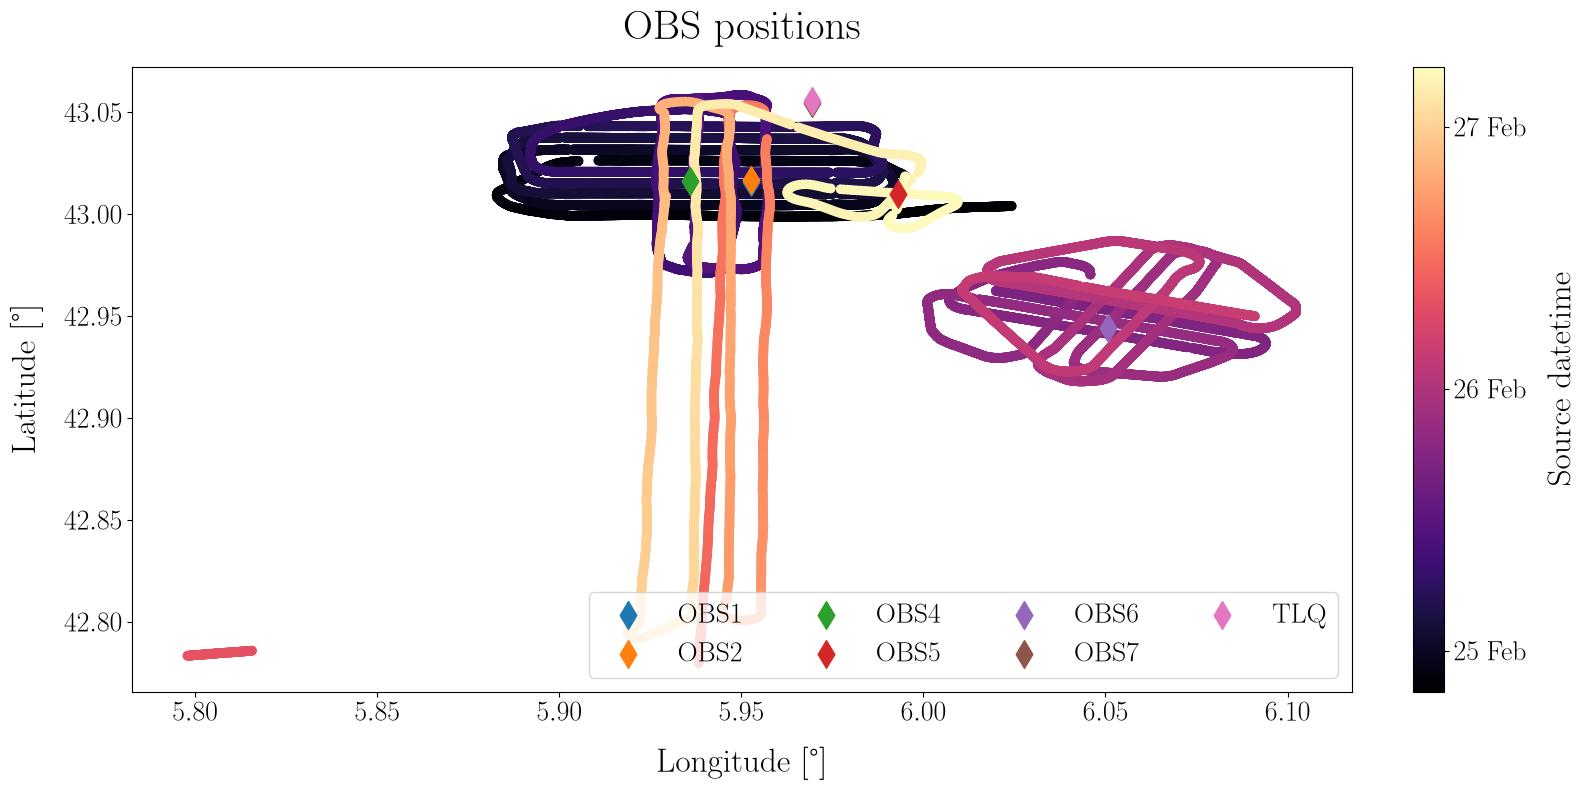

In [44]:
fig, ax = plt.subplots()

dates = ds_pos.src_datetime.values
date_num = mdates.date2num(dates)

sc = ax.scatter(
    ds_pos.tir_src_lon,
    ds_pos.tir_src_lat,
    c=date_num,
    cmap="magma",
)

plot_obs_pos(ds_pos, ax=ax)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Source datetime")
cbar.ax.yaxis.set_major_locator(mdates.DayLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

In [45]:
filter1_stop = datetime(2026, 2, 25, 16, 40, 0)
ds_pos_filtered = ds_pos.copy()
ds_pos_filtered1 = ds_pos_filtered.sel(src_datetime=slice(ds_pos_filtered.src_datetime.values[0], filter1_stop))

filter2_start = datetime(2026, 2, 26, 4, 0, 0)
ds_pos_filtered2 = ds_pos_filtered.sel(src_datetime=slice(filter2_start, ds_pos_filtered.src_datetime.values[-1]))

ds_pos_filtered1.src_datetime, ds_pos_filtered2.src_datetime

(<xarray.DataArray 'src_datetime' (src_datetime: 18528)> Size: 148kB
 array(['2026-02-24T20:14:06.600098000', '2026-02-24T20:14:09.600098000',
        '2026-02-24T20:14:12.600098000', ..., '2026-02-25T11:52:18.600098000',
        '2026-02-25T11:52:21.600098000', '2026-02-25T11:52:24.600098000'],
       shape=(18528,), dtype='datetime64[ns]')
 Coordinates:
   * src_datetime  (src_datetime) datetime64[ns] 148kB 2026-02-24T20:14:06.600...,
 <xarray.DataArray 'src_datetime' (src_datetime: 2289)> Size: 18kB
 array(['2026-02-26T07:59:48.800049000', '2026-02-26T07:59:51.800049000',
        '2026-02-26T07:59:54.800049000', ..., '2026-02-27T05:29:30.200073000',
        '2026-02-27T05:30:00.200073000', '2026-02-27T05:30:30.200073000'],
       shape=(2289,), dtype='datetime64[ns]')
 Coordinates:
   * src_datetime  (src_datetime) datetime64[ns] 18kB 2026-02-26T07:59:48.8000...)

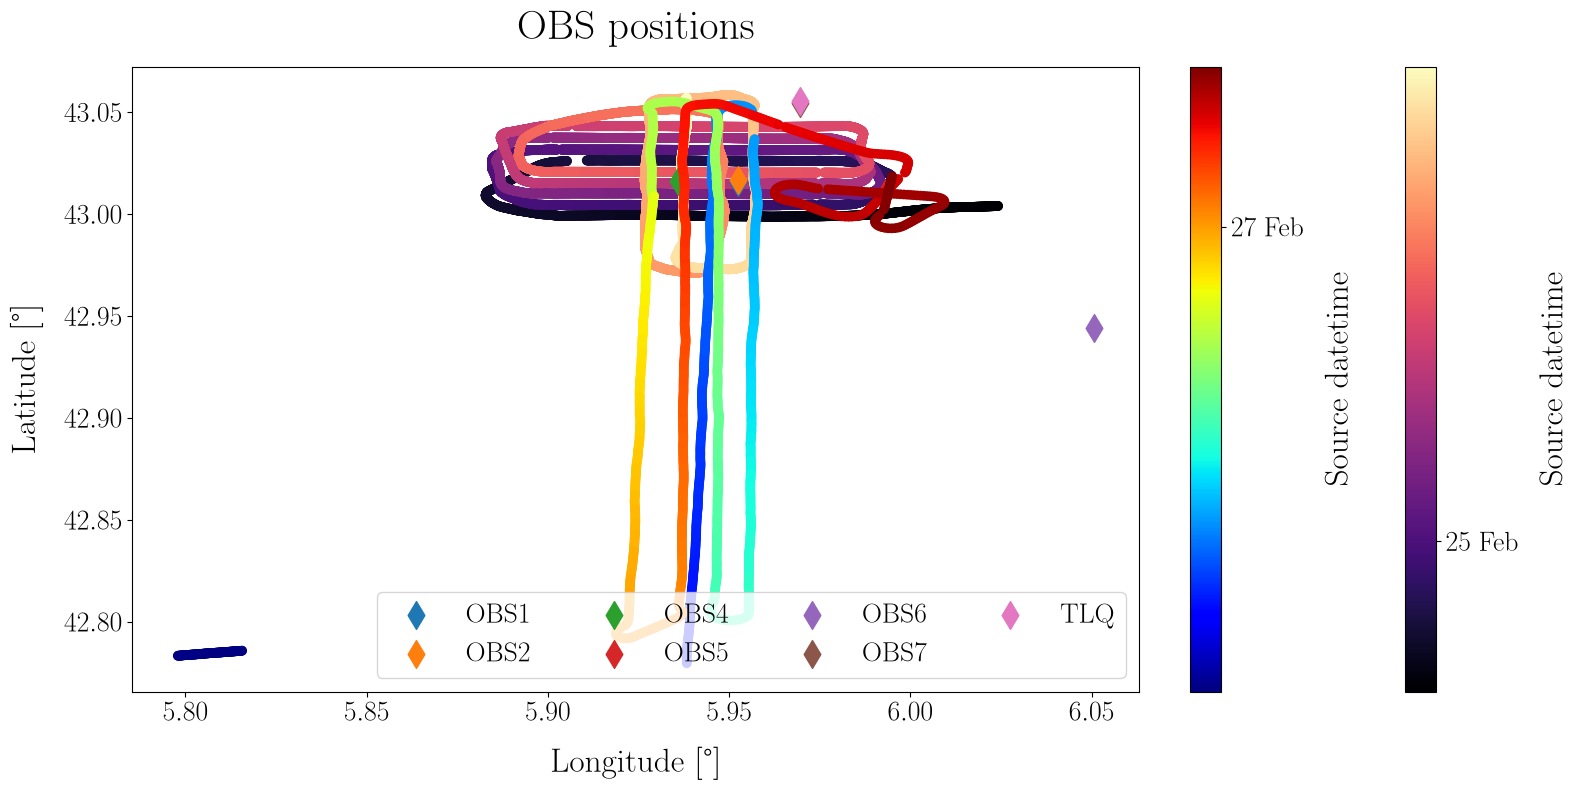

In [46]:
fig, ax = plt.subplots()

dates = ds_pos_filtered1.src_datetime.values
date_num = mdates.date2num(dates)

sc = ax.scatter(
    ds_pos_filtered1.tir_src_lon,
    ds_pos_filtered1.tir_src_lat,
    c=date_num,
    cmap="magma",
)

plot_obs_pos(ds_pos_filtered1, ax=ax)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Source datetime")
cbar.ax.yaxis.set_major_locator(mdates.DayLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

dates = ds_pos_filtered2.src_datetime.values
date_num = mdates.date2num(dates)

sc = ax.scatter(
    ds_pos_filtered2.tir_src_lon,
    ds_pos_filtered2.tir_src_lat,
    c=date_num,
    cmap="jet",
)


cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Source datetime")
cbar.ax.yaxis.set_major_locator(mdates.DayLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))


Une fois la portion émise au dessus de l'OBS 6 retirée on peut filtrer. 

In [72]:
apply_selection = False

if apply_selection:

    valid_events = []
    for name, node in portion_event.position.children.items():
        
        if name in event_to_drop:   # Dropped according to frist condition 
            continue 

        ds_position_event = node.to_dataset()

        event_start = ds_position_event.start_datetime.values
        event_stop = ds_position_event.stop_datetime.values

        # First option : filter to avoid any emission 
        # event_stops_before_first_emission = ds_pos_filtered.src_datetime.values[0] >= event_stop
        # event_starts_after_last_emission = ds_pos_filtered.src_datetime.values[-1] <= event_start
        # valid_event = event_stops_before_first_emission or event_starts_after_last_emission

        # Second option keep event if emission are emitted clsoe to OBS 6 
        event_stops_before_first_emission1 = ds_pos_filtered1.src_datetime.values[0] >= event_stop
        event_starts_after_last_emission1 = ds_pos_filtered1.src_datetime.values[-1] <= event_start
        valid_event1 = event_stops_before_first_emission1 or event_starts_after_last_emission1

        event_stops_before_first_emission2 = ds_pos_filtered2.src_datetime.values[0] >= event_stop
        event_starts_after_last_emission2 = ds_pos_filtered2.src_datetime.values[-1] <= event_start
        valid_event2 = event_stops_before_first_emission2 or event_starts_after_last_emission2

        valid_event = valid_event1 and valid_event2
        if valid_event:
            valid_events.append(name)

else:
    # valid_events = [name for name in list(portion_event.position.children) if name not in event_to_drop]
    valid_events = ["event_83"]

In [68]:
valid_events

['event_13', 'event_83', 'event_84']

Avec la seconde option on conserve davantage d'évenements. 

In [73]:
# Rebuild datatree with correct event names once unvalid ones have been dropped
portion_event_filter = xr.DataTree()

for e_id_new, event_name in enumerate(valid_events):
    
    path_pos = f"position/{event_name}"
    new_path_pos = f"position/event_{e_id_new}"
    old_pos_event = portion_event[path_pos].to_dataset()
    old_pos_event.attrs["event_id"] = e_id_new
    portion_event_filter[new_path_pos] = old_pos_event

    # path_press = f"pressure/{event_name}"
    # new_path_press = f"pressure/event_{e_id_new}"
    # old_press_event = portion_event[path_press].to_dataset()
    # old_press_event.attrs["event_id"] = e_id_new
    # portion_event_filter[new_path_press] = old_press_event

portion_event_filter["event_id"] = np.arange(len(valid_events))
portion_event_filter.attrs = portion_event.attrs

del portion_event
portion_event = portion_event_filter.copy()
del portion_event_filter

In [64]:
portion_event

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 1)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 8B 0
│   Attributes:
│       box_lon_min:  5.919009015
│       box_lon_max:  5.965350184499999
│       box_lat_min:  42.973826338
│       box_lat_max:  43.07525886599999
└── Group: /position
    └── Group: /position/event_0
            Dimensions:         (datetime: 57)
            Coordinates:
              * datetime        (datetime) datetime64[ns] 456B 2026-02-25T10:28:20 ... 20...
            Data variables:
                lon             (datetime) float64 456B 5.965 5.964 5.963 ... 5.92 5.92
                lat             (datetime) float64 456B 43.05 43.05 43.05 ... 43.04 43.04
                start_datetime  datetime64[ns] 8B 2026-02-25T10:28:20
                stop_datetime   datetime64[ns] 8B 2026-02-25T10:37:40
            Attributes:
                description:              Positions AIS interpolées
                interpolation_time_step:  10s
                campagne:                 ACOUPLANE
                geodesic_frame:           WGS84
                event_id:                 0
                MMSI:                     61

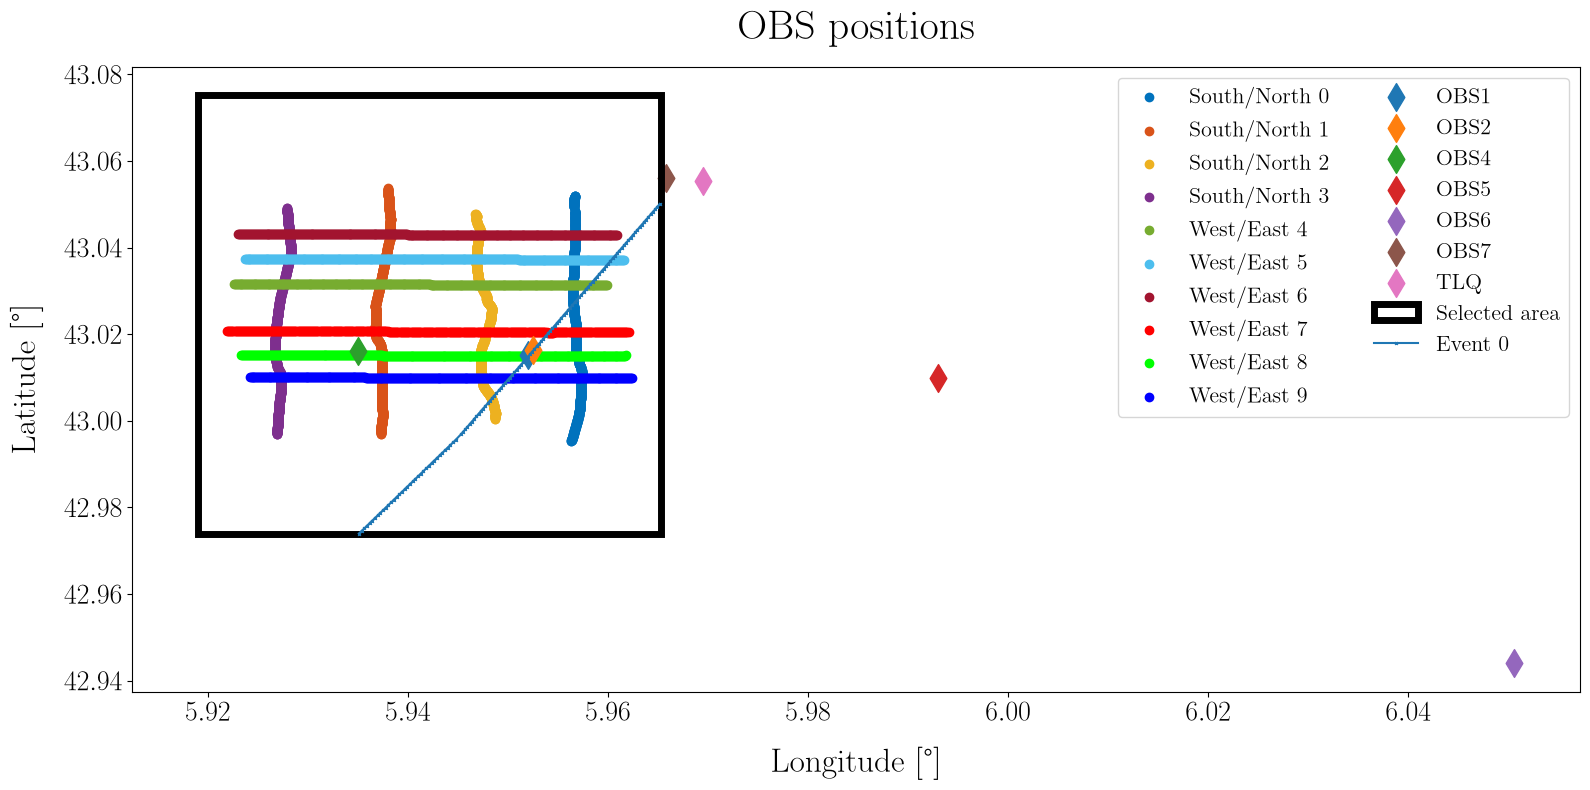

In [74]:
# Plot
fig, ax = plot_portion_tir_pos(portion_tree=portion)
ax.add_patch(
    Rectangle(
        (portion_event.box_lon_min, portion_event.box_lat_min),
        portion_event.box_lon_max - portion_event.box_lon_min,
        portion_event.box_lat_max - portion_event.box_lat_min,
        fc="none",
        ec="k",
        lw=5,
        label="Selected area",
    )
)

for name, node in portion_event.position.children.items():
    ds_position_section = node.to_dataset()
    plt.plot(
        ds_position_section.lon, ds_position_section.lat, "-x", markersize=2, label=f"Event {ds_position_section.event_id}"
    )

ax.legend()
legend = ax.get_legend()

if legend is not None:
    handles = legend.legend_handles
    labels = [text.get_text() for text in legend.get_texts()]

    legend.remove()

    ax.legend(
        handles,
        labels,
        loc="upper right",
        fontsize=16,
        ncols=2,
    )

Avec la seconde option on conserve tout de même quelques trajectoires exploitables. Reste à vérfier que le SNR est suffisament bon par rapport aux émissions. Les deux trajectoires réellement exploitable sont les event 3 et 7.  

In [75]:
# # Plot
# # Illustrate on map by batches of 10
# idx_mmsi_min = 0
# mmsi_batch_size = 10
# while idx_mmsi_min < ds_ais_in_area.sizes["mmsi"]:
#     ds_ais_in_area_batch = ds_ais_in_area.isel(mmsi=slice(idx_mmsi_min, idx_mmsi_min+mmsi_batch_size))
#     idx_mmsi_min += mmsi_batch_size

#     fig, ax = plot_portion_tir_pos(portion_tree=portion)
#     ax.add_patch(
#         Rectangle(
#             (lon_min, lat_min),
#             lon_max - lon_min,
#             lat_max - lat_min,
#             fc="none",
#             ec="k",
#             lw=5,
#             label="Selected area",
#         )
#     )

#     for m in ds_ais_in_area_batch.mmsi.values:
#         # print(m)
#         pos_mmsi = ds_ais_in_area_batch.sel(mmsi=m)
#         plt.plot(pos_mmsi.ais_lon, pos_mmsi.ais_lat, "-x", markersize=2, label=m)

#     ax.legend()
#     legend = ax.get_legend()

#     if legend is not None:
#         handles = legend.legend_handles
#         labels = [text.get_text() for text in legend.get_texts()]

#         legend.remove()

#         ax.legend(
#             handles,
#             labels,
#             loc="upper right",
#             fontsize=16,
#             ncols=2,
#         )


<!-- Il y a bon nombre de trajectoires qui semblent exploitables. 

On peut sélectionner quelques trajectoires particulièrement intéressantes : 

* MMSI = 3 : trajectoire coudée, changement de cap au milieu de la grille 
* MMSI = 13, 17 : trajectoires zonales qui coïncident avec la section OE 4
* MMSi = 31 : diagonale NE -> SO 
* MMSI = 51 : diagonale NO -> SE
* MMSI = 61 : diagonale NE -> SO, plusieurs passages du même navire  -->

In [76]:
# mmsi_selection = [3, 13, 17, 31, 51, 61]
# ds_ais_selection = ds_ais_in_area.sel(mmsi=mmsi_selection)
# ds_ais_selection

In [77]:
# # Plot to check every thing is ok
# fig, ax = plot_portion_tir_pos(portion_tree=portion)
# ax.add_patch(
#     Rectangle(
#         (lon_min, lat_min),
#         lon_max - lon_min,
#         lat_max - lat_min,
#         fc="none",
#         ec="k",
#         lw=5,
#         label="Selected area",
#     )
# )

# for isec, pos_sec in enumerate(event_sections):
#     plt.plot(pos_sec.ais_lon, pos_sec.ais_lat, "-x", markersize=2, label=f"Event {isec}")

# # for m in ds_ais_selection.mmsi.values:
# #     pos_mmsi = ds_ais_selection.sel(mmsi=m)
# #     plt.plot(pos_mmsi.ais_lon, pos_mmsi.ais_lat, "-x", markersize=2, label=m)

# ax.legend()
# legend = ax.get_legend()

# if legend is not None:
#     handles = legend.legend_handles
#     labels = [text.get_text() for text in legend.get_texts()]

#     legend.remove()

#     ax.legend(
#         handles, 
#         labels,
#         loc="upper right",
#         fontsize=16,
#         ncols=2,
#     )

On peut vérifier 

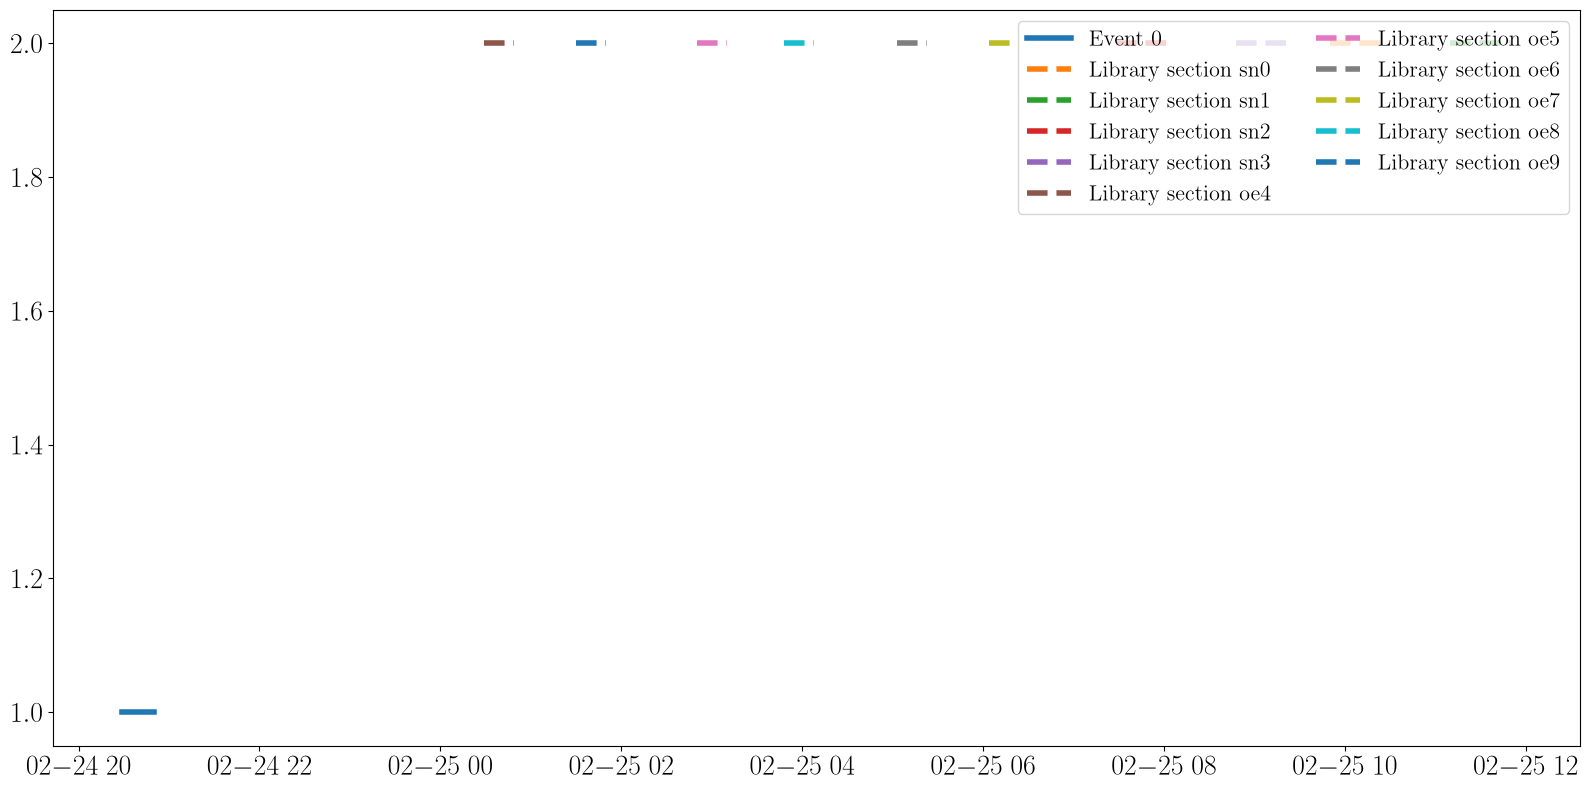

In [78]:
# Common period
plt.figure()

for name, node in portion_event.position.children.items():
    ds_position_section = node.to_dataset()
    plt.plot(
        ds_position_section.datetime,
        np.ones(ds_position_section.datetime.size),
        label=f"Event {name.split('_')[1]}",
        linewidth=4,
    )

for name, node in portion.position.children.items():
    ds_position_section = node.to_dataset()
    plt.plot(
        ds_position_section.src_datetime,
        2 * np.ones(ds_position_section.src_datetime.size),
        label=f"Library section {name}",
        linewidth=4,
        linestyle="--"
    )

plt.legend(ncol=2, loc="upper right", fontsize=16)

A priori pas de recouvrement des trajectoires sélectionnées et des émissions constituant la lirbairie. Il faut néanmoins s'assurer que les données de pressions sont exploitables (disponibilité et SNR des signaux de navires).

# Extraction signaux associés aux navires sélectionnés 

## Extraction et stockage 

In [79]:
event_to_drop = []
for name, node in portion_event.position.children.items():
    ds_position_event = node.to_dataset()

    event_start = ds_position_event.start_datetime.values
    event_stop = ds_position_event.stop_datetime.values

    invalid_event = False
    for obs_id in ds_pressure.obs_id.values:
        # Check if any data is available 
        event_stops_before_recording = obs_datetimes[obs_id][0] >= event_stop
        event_starts_after_recording = obs_datetimes[obs_id][-1] <= event_start
        no_data = event_stops_before_recording or event_starts_after_recording
        if no_data:
            print(f"OBS '{obs_id}' has no data between {event_start} and {event_stop} (recording spans {obs_datetimes[obs_id][0]} -> {obs_datetimes[obs_id][-1]}).")
            invalid_event = True


    if invalid_event:
        # portion_event.drop_nodes()
        print(f"Event {name} dropped")
        event_to_drop.append(name)
        continue

    ds_pressure_event = extract_pressure_section(
        event_start,
        event_stop,
        ds_pressure,
        obs_datetimes,
    )
    ds_pressure_event = convert_raw_pressure_to_physical_units(
        ds_pressure=ds_pressure_event
    )
    
    ds_pressure_event.attrs["event_id"] = ds_position_event.event_id
    
    # Store in event portion
    path = f"pressure/event_{ds_position_event.event_id}"
    portion_event[path] = ds_pressure_event

In [80]:
portion_event 

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 1)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 8B 0
│   Attributes:
│       box_lon_min:  5.919009015
│       box_lon_max:  5.965350184499999
│       box_lat_min:  42.973826338
│       box_lat_max:  43.07525886599999
├── Group: /position
│   └── Group: /position/event_0
│           Dimensions:         (datetime: 127)
│           Coordinates:
│             * datetime        (datetime) datetime64[ns] 1kB 2026-02-24T20:28:50 ... 202...
│           Data variables:
│               lon             (datetime) float64 1kB 5.935 5.935 5.936 ... 5.965 5.965
│               lat             (datetime) float64 1kB 42.97 42.97 42.98 ... 43.05 43.05
│               start_datetime  datetime64[ns] 8B 2026-02-24T20:28:50
│               stop_datetime   datetime64[ns] 8B 2026-02-24T20:49:50
│           Attributes:
│               description:              Positions AIS interpolées
│               interpolation_time_step:  10s
│               campagne:                 ACOUPLANE
│               geodesic_frame:           WGS84
│               event_id:                 0
│               MMSI:                     61
└── Group: /pressure
    └── Group: /pressure/event_0
            Dimensions:         (time_obs1: 2520001, time_obs2: 2520001,
                                 time_obs4: 2520001, time_obs5: 2520001,
                                 time_obs6: 2520001, time_obs7: 2520001, obs_id: 6)
            Coordinates:
              * time_obs1       (time_obs1) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
              * time_obs2       (time_obs2) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
              * time_obs4       (time_obs4) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
              * time_obs5       (time_obs5) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
              * time_obs6       (time_obs6) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
              * time_obs7       (time_obs7) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
              * obs_id          (obs_id) <U4 96B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'
            Data variables:
                pressure_obs1   (time_obs1) float64 20MB 0.02825 0.02519 ... 0.03389 0.03299
                pressure_obs2   (time_obs2) float64 20MB 0.02734 0.02412 ... 0.02825 0.02757
                pressure_obs4   (time_obs4) float64 20MB 0.03728 0.02899 ... 0.02289 0.02615
                pressure_obs5   (time_obs5) float64 20MB 0.01351 0.004117 ... 0.03194
                pressure_obs6   (time_obs6) float64 20MB 0.02405 0.02158 ... 0.01682 0.02406
                pressure_obs7   (time_obs7) float64 20MB 0.03372 0.03059 ... 0.06347 0.05318
                start_datetime  (obs_id) datetime64[ns] 48B ...
            Attributes:
                description:  Données de pression (voie hydro 3)
                campagne:     ACOUPLANE
                fs:           2000
                fullscale:    4.52
                event_id:     0

In [81]:
# debug not usefull anymore
# for name, node in portion_event.pressure.children.items():
#     ds_pressure_event = node.to_dataset()
#     ds_pressure_event.attrs["event_id"] = int(name.split("_")[-1])

#     node.ds = ds_pressure_event
# portion_event

In [82]:
# # Get the IDs of the events you want to drop
# dropped_event_ids = [
#     int(e_name.split("_")[-1])
#     for e_name in event_to_drop
# ]
# # Keep only the event IDs that were not dropped
# new_event_ids = [
#     e_id
#     for e_id in portion_event["event_id"].values
#     if e_id not in dropped_event_ids
# ]
# new_event_ids

In [83]:
# # Rebuild datatree with correct event names once unvalid ones have been dropped
# portion_event_filter = xr.DataTree()

# for e_id_new, e_id in enumerate(new_event_ids):
#     print(e_id_new)
    
#     path_pos = f"position/event_{e_id}"
#     new_path_pos = f"position/event_{e_id_new}"
#     old_pos_event = portion_event[path_pos].to_dataset()
#     old_pos_event.attrs["event_id"] = e_id_new
#     portion_event_filter[new_path_pos] = old_pos_event

#     path_press = f"pressure/event_{e_id}"
#     new_path_press = f"pressure/event_{e_id_new}"
#     old_press_event = portion_event[path_press].to_dataset()
#     old_press_event.attrs["event_id"] = e_id_new
#     portion_event_filter[new_path_press] = old_press_event

# portion_event_filter["event_id"] = np.arange(len(new_event_ids))
# portion_event_filter.attrs = portion_event.attrs

# # del portion_event
# # portion_event = portion_event_.copy()
# # del portion_event_

In [84]:
# portion_event_filter

## Visualisation des signaux 

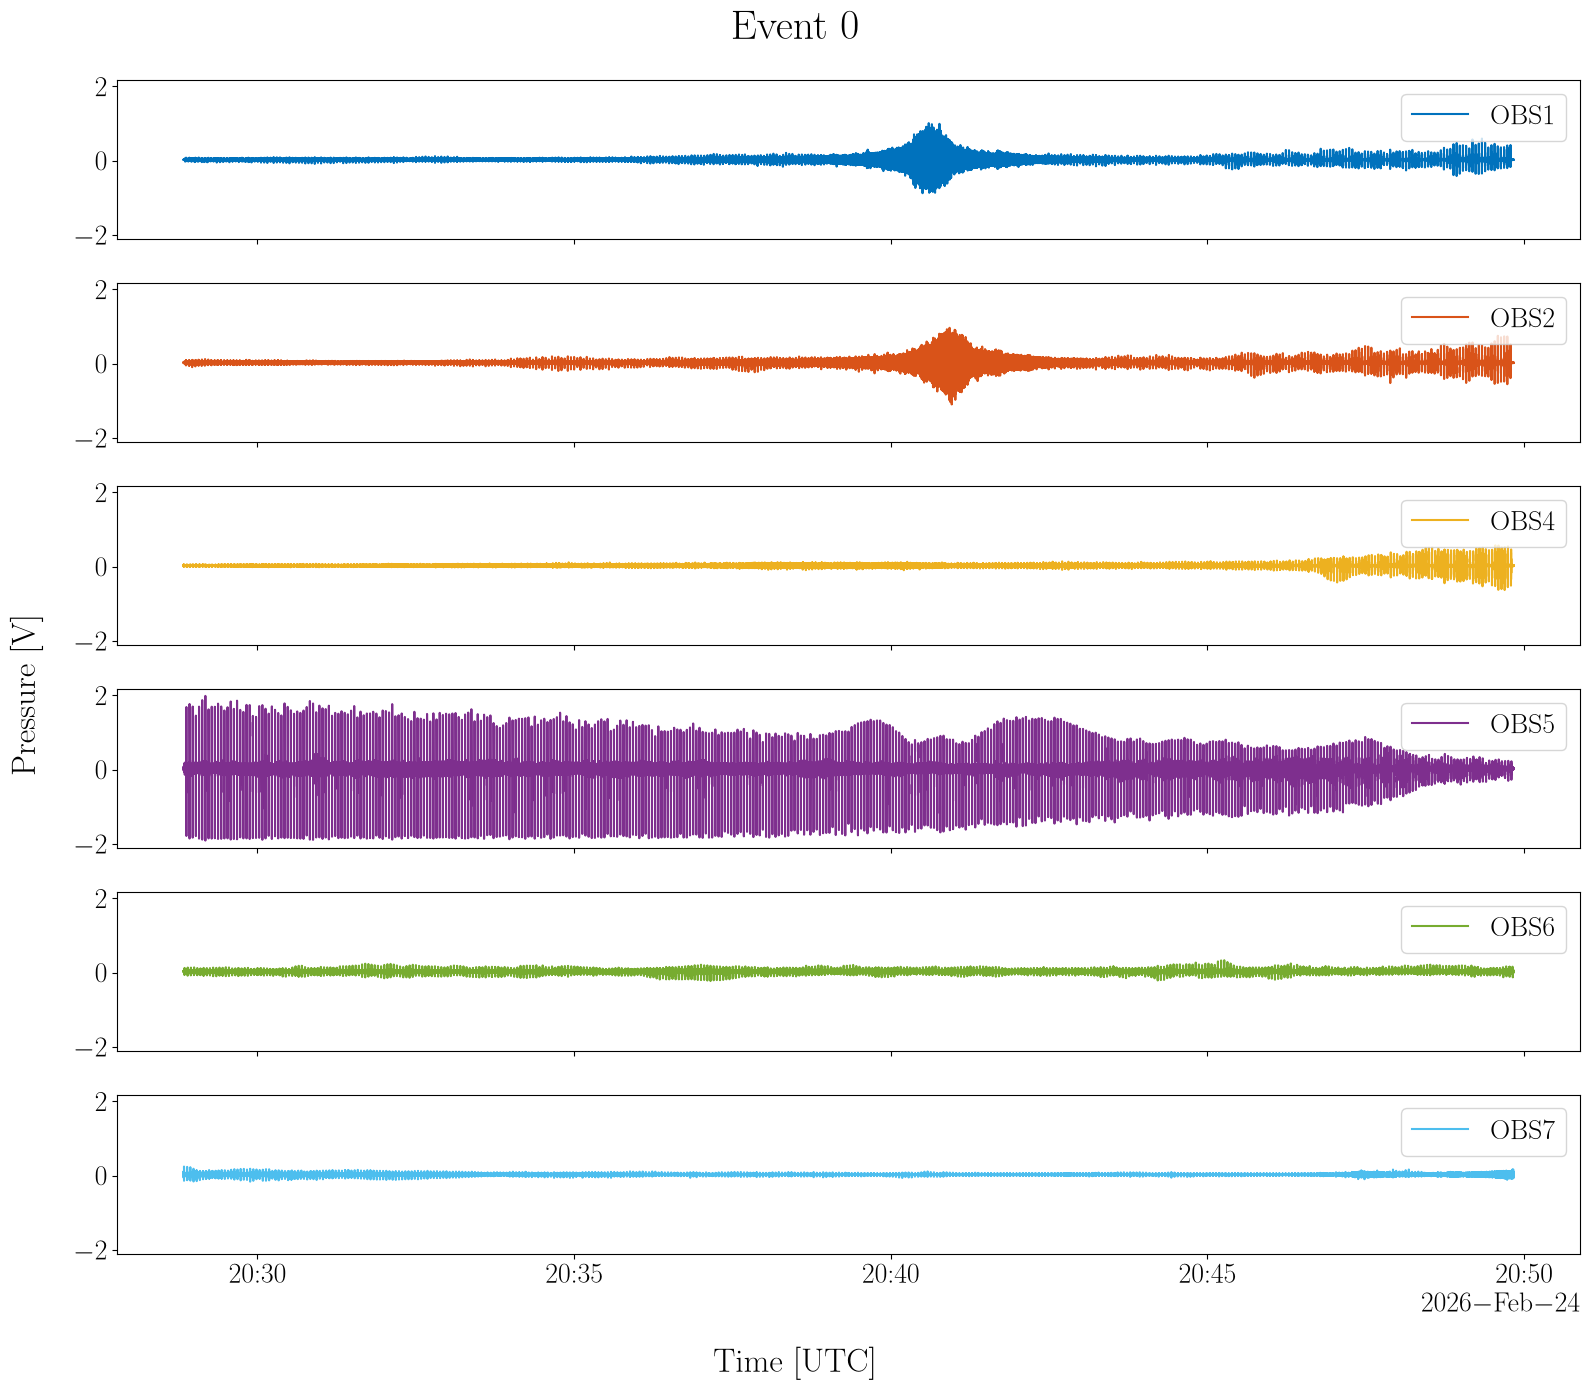

In [85]:
# Plot
single_fig = False
for name, node in portion_event.pressure.children.items():
    ds_pressure_section = node.to_dataset()
    fig, axs = plot_pressure_section(ds_pressure_section=ds_pressure_section, single_fig=single_fig)
    fig.suptitle(f"Event {ds_pressure_section.event_id}")
    plt.show()

## Spectrogrames 


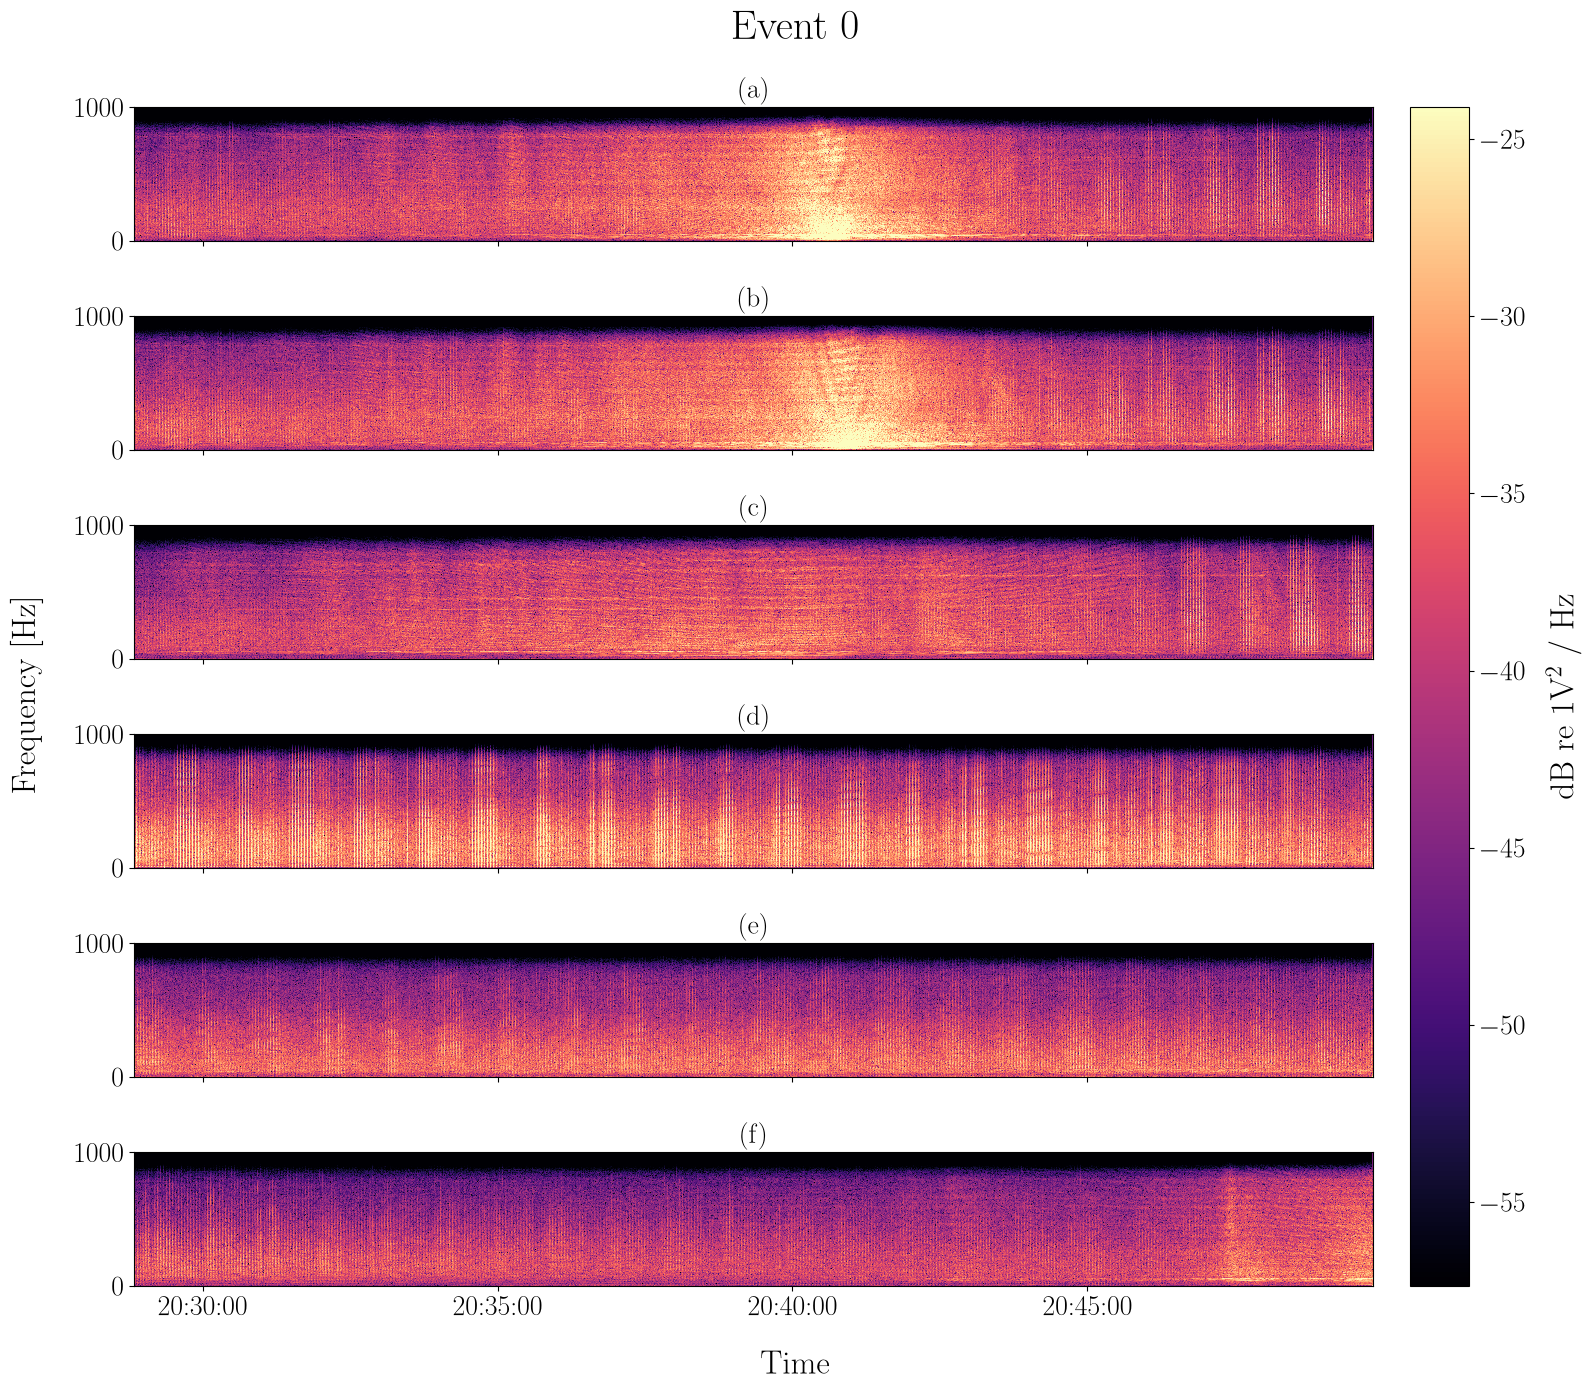

In [86]:
# Plot
for name, node in portion_event.pressure.children.items():
    ds_pressure_section = node.to_dataset()
    try:
        fig, axs = plot_spectrogram_section(ds_pressure_section, nperseg=2**10, noverlap=2**9, cmap="magma")
    except:
        print(f"Data with different length event : {name}")
    fig.suptitle(f"Event {ds_pressure_section.event_id}")
    plt.show()

# Sauvergarde de la portion event 

In [ ]:
# Save as netcdf
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event_ais.nc"
portion_event.attrs["portion_filepath"] = fpath
portion_event.to_netcdf(fpath)